<a href="https://colab.research.google.com/github/RoihansLab/Data-Mining-Project/blob/main/youtube_comment_sentiment/Zero-Shot_Labeling/Salinan_dari_Pre_trained_Transformer_baru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Analisis Sentimen Publik terhadap AI yang Menggantikan Pekerjaan Manusia**

**Mata Kuliah:** Data Mining

**Nama Anggota Kelompok:**

1.   Muhammad Rafa Enrico (Ketua)
2.   Roihan Saputra

**Kelas TI-3C**

**Program Studi:** D4 Teknologi Rekayasa Komputer, Politeknik Negeri Semarang

## Rumusan Masalah
1. Bagaimana sebaran sentimen publik (positif, negatif, netral) terhadap isu AI yang menggantikan pekerjaan manusia berdasarkan komentar YouTube?
2. Algoritma klasifikasi mana di antara Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression yang memberikan performa terbaik untuk diimplementasikan sebagai model otomatisasi deteksi sentimen publik?

## Tujuan
1. Mengetahui sebaran sentimen publik terhadap isu AI yang menggantikan pekerjaan manusia.
2. Menemukan model klasifikasi yang paling tangguh (robust) untuk mengotomatisasi proses pelabelan sentimen pada data komentar di masa depan.

# **1. Import Library**

In [1]:
%pip install youtube-comment-downloader langdetect lingua-language-detector transformers torch emoji sentencepiece tiktoken --quiet
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from langdetect import detect, detect_langs, DetectorFactory, LangDetectException
from lingua import Language, LanguageDetectorBuilder
from transformers import pipeline
import torch
import joblib
import re
import os
import unicodedata
from tqdm import tqdm
from collections import Counter


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 23.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.3/170.3 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 30.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 17.4 MB/s eta 0:00:00


# **2. Load Datasets and Data Understanding**

**Fitur yang Kami Ambil:**
1. `video_url`: URL dari 6 video YouTube yang menjadi sumber data.
2. `author`: nama akun penulis komentar.
3. `comment`: isi teks komentar.
4. `likes`: jumlah *like* pada komentar.
5. `time`: waktu komentar dibuat, relatif terhadap tanggal *web scraping* dilakukan.


In [2]:
# Deteksi otomatis lokasi dataset (Google Colab vs VSCode / Lokal)
if os.path.exists('/content/youtube_comments.csv'):
    # Google Colab
    path_data = '/content/youtube_comments.csv'
elif os.path.exists('../../datasets/youtube_comments.csv'):
    # VSCode (dijalankan dari folder notebook)
    path_data = '../../datasets/youtube_comments.csv'
elif os.path.exists('datasets/youtube_comments.csv'):
    # VSCode (dijalankan dari root project)
    path_data = 'datasets/youtube_comments.csv'
else:
    path_data = 'youtube_comments.csv'

df = pd.read_csv(path_data)
print(f"Data mentah dimuat dari: {path_data} ({len(df)} baris)")
jumlah_baris_awal = len(df)  # dipakai pada ringkasan akhir (3.15)
df


,video_url,author,comment,likes,time
0,https://www.youtube.com/watch?v=t2WmNcToB3I,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,2 maanden geleden
1,https://www.youtube.com/watch?v=t2WmNcToB3I,@robidarmawan71198,Menurut saya jika semua pengusaha berpikiran s...,189,2 maanden geleden
2,https://www.youtube.com/watch?v=t2WmNcToB3I,@wooshstar,jujur ya sebagai seorang yang bekerja di bidan...,6,2 maanden geleden (bewerkt)
3,https://www.youtube.com/watch?v=t2WmNcToB3I,@kadaladal7,Gw sebagai illustrator susah bener dapet klien...,588,2 maanden geleden
4,https://www.youtube.com/watch?v=t2WmNcToB3I,@Bagas_betok,Niat untung -> efesiensi phk->produksi mening...,85,2 maanden geleden
...,...,...,...,...,...
4453,https://www.youtube.com/watch?v=0LOHWGQwKtM,@HMF-7s,There’s a real awakening that cannot be stoppe...,0,5 maanden geleden
4454,https://www.youtube.com/watch?v=0LOHWGQwKtM,@fr0z3nk0,I'm a software engineer with 20 years of exper...,0,5 maanden geleden (bewerkt)
4455,https://www.youtube.com/watch?v=0LOHWGQwKtM,@nalen5050,so many way to discard that... I'll just take ...,2,5 maanden geleden
4456,https://www.youtube.com/watch?v=0LOHWGQwKtM,@georgioszampoukis,@nalen5050 Are you a software engineer? Beca...,0,5 maanden geleden


**Hasil `info()`:**

Seluruh kolom hasil *web scraping* bertipe `object` (string/kategorikal), termasuk kolom `likes` yang seharusnya berupa angka. Jumlah baris data yang kami miliki adalah 4.458.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4458 entries, 0 to 4457
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   video_url  4458 non-null   object
 1   author     4458 non-null   object
 2   comment    4458 non-null   object
 3   likes      4458 non-null   object
 4   time       4458 non-null   object
dtypes: object(5)
memory usage: 174.3+ KB


**Hasil dari Describe :**

1. count (Jumlah data) : Total baris data yang terisi (tidak kosong/null) pada kolom tersebut.
2. Unique (Keunikan / Variasi Data): Jumlah nilai yang benar-benar berbeda (tidak kembar) di dalam kolom tersebut.
3. Top (Nilai Paling Sering Muncul / Modus) : Data atau teks apa yang frekuensi kemunculannya paling tinggi di kolom itu.
4. Freq (Frequency / Frekuensi) :
Seberapa banyak si nilai top tadi muncul di dalam dataset.


Tabel ini menunjukkan karakteristik data teks kami. Count adalah total data yang kami miliki, Unique menunjukkan seberapa banyak variasi datanya, Top adalah isi data yang paling dominan atau sering muncul, dan Freq menunjukkan berapa kali nilai Top tersebut muncul di dalam dataset

In [4]:
df.describe().T

,count,unique,top,freq
video_url,4458,6,https://www.youtube.com/watch?v=7Pq-S557XQU,1500
author,4458,3320,@edward-broo,36
comment,4458,4406,Up,6
likes,4458,241,0,2400
time,4458,62,2 maanden geleden,933


# **3. Preprocessing Data**

Pada tahap preprocessing, kami menerapkan pendekatan yang sistematis dan terstruktur untuk memastikan kualitas data mentah sebelum masuk ke tahap analisis dan pemodelan.

## **3.1 Nilai Kosong (Null)**

**Intinya:** Nilai kosong (null) adalah kolom yang tidak berisi data apa pun, seperti sel kosong di Excel. Baris seperti ini tidak dapat dipakai model sehingga dibuang.

**Contoh:** komentar yang kolom `comment`-nya kosong tidak memuat opini, sehingga barisnya dihapus. (Pada data kami tidak ditemukan nilai kosong.)

**Mengapa nilai kosong (null) harus ditangani?**

1. **Menyebabkan error saat pelatihan model:** Sebagian besar algoritma *machine learning*, termasuk Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression yang kami gunakan, bekerja dengan operasi numerik seperti perkalian matriks dan perhitungan jarak vektor. Algoritma tersebut tidak dapat mengolah nilai kosong (NaN/null), sehingga proses pelatihan akan menghasilkan error.

2. **Tidak mengandung informasi:** Dalam analisis sentimen, komentar yang bernilai null tidak memuat opini apa pun sehingga tidak ada pola yang dapat dipelajari oleh model.

3. **Mengganggu ekstraksi fitur:** Pada tahap ekstraksi fitur menggunakan TF-IDF, baris tanpa teks dapat membuat matriks representasi kata menjadi tidak konsisten.

In [5]:
df.isnull().sum()

,0
video_url,0
author,0
comment,0
likes,0
time,0


**Hasil pengecekan:**

ditemukan bahwa terdapat nilai kosong pada bagian likes dan time

## **3.2 Data Duplikat**

**Intinya:** Baris duplikat adalah baris yang isinya sama persis di semua kolom (video, penulis, komentar, jumlah *like*, dan waktu), sehingga hanya salinan. Satu baris disimpan dan salinannya dihapus.

**Contoh:** baris yang muncul dua kali dengan isi yang persis sama dihitung sebagai 1 baris saja.

**Mengapa data duplikat harus dihapus?**

1. **Mencegah kebocoran data (*data leakage*):** Saat data dibagi menjadi data latih dan data uji (misalnya 80:20), kalimat yang sama dapat masuk ke kedua bagian sekaligus. Akibatnya, model diuji menggunakan data yang sudah pernah dilihat saat pelatihan.

2. **Mencegah akurasi semu:** Kebocoran data tersebut dapat membuat akurasi model tampak sangat tinggi, padahal model hanya "menghafal" komentar duplikat, bukan memahami pola kalimat baru.

3. **Mencegah bias bobot kata:** Jika satu komentar (misalnya komentar spam atau bot) muncul berkali-kali, kata-kata di dalamnya akan dianggap terlalu penting dalam pembobotan TF-IDF sehingga model menjadi bias.

4. **Efisiensi komputasi:** Memproses teks yang sama berulang kali hanya menambah penggunaan memori dan waktu pelatihan tanpa menambah informasi baru.

In [6]:
df.duplicated().sum()

np.int64(11)

**Hasil pengecekan:**

Ditemukan **11 baris duplikat**, yaitu baris yang identik pada seluruh kolom (video, penulis, isi komentar, jumlah *like*, dan waktu). Tabel di atas menampilkan baris asli beserta salinannya secara berurutan. Baris pertama dari setiap kelompok dipertahankan, sedangkan salinannya dihapus.

In [7]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [8]:
df

,video_url,author,comment,likes,time
0,https://www.youtube.com/watch?v=t2WmNcToB3I,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,2 maanden geleden
1,https://www.youtube.com/watch?v=t2WmNcToB3I,@robidarmawan71198,Menurut saya jika semua pengusaha berpikiran s...,189,2 maanden geleden
2,https://www.youtube.com/watch?v=t2WmNcToB3I,@wooshstar,jujur ya sebagai seorang yang bekerja di bidan...,6,2 maanden geleden (bewerkt)
3,https://www.youtube.com/watch?v=t2WmNcToB3I,@kadaladal7,Gw sebagai illustrator susah bener dapet klien...,588,2 maanden geleden
4,https://www.youtube.com/watch?v=t2WmNcToB3I,@Bagas_betok,Niat untung -> efesiensi phk->produksi mening...,85,2 maanden geleden
...,...,...,...,...,...
4453,https://www.youtube.com/watch?v=0LOHWGQwKtM,@HMF-7s,There’s a real awakening that cannot be stoppe...,0,5 maanden geleden
4454,https://www.youtube.com/watch?v=0LOHWGQwKtM,@fr0z3nk0,I'm a software engineer with 20 years of exper...,0,5 maanden geleden (bewerkt)
4455,https://www.youtube.com/watch?v=0LOHWGQwKtM,@nalen5050,so many way to discard that... I'll just take ...,2,5 maanden geleden
4456,https://www.youtube.com/watch?v=0LOHWGQwKtM,@georgioszampoukis,@nalen5050 Are you a software engineer? Beca...,0,5 maanden geleden


In [9]:
df = df.drop(columns=["likes", "time"])
df


,video_url,author,comment
0,https://www.youtube.com/watch?v=t2WmNcToB3I,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol d...
1,https://www.youtube.com/watch?v=t2WmNcToB3I,@robidarmawan71198,Menurut saya jika semua pengusaha berpikiran s...
2,https://www.youtube.com/watch?v=t2WmNcToB3I,@wooshstar,jujur ya sebagai seorang yang bekerja di bidan...
3,https://www.youtube.com/watch?v=t2WmNcToB3I,@kadaladal7,Gw sebagai illustrator susah bener dapet klien...
4,https://www.youtube.com/watch?v=t2WmNcToB3I,@Bagas_betok,Niat untung -> efesiensi phk->produksi mening...
...,...,...,...
4453,https://www.youtube.com/watch?v=0LOHWGQwKtM,@HMF-7s,There’s a real awakening that cannot be stoppe...
4454,https://www.youtube.com/watch?v=0LOHWGQwKtM,@fr0z3nk0,I'm a software engineer with 20 years of exper...
4455,https://www.youtube.com/watch?v=0LOHWGQwKtM,@nalen5050,so many way to discard that... I'll just take ...
4456,https://www.youtube.com/watch?v=0LOHWGQwKtM,@georgioszampoukis,@nalen5050 Are you a software engineer? Beca...


## **3.2 Perubahan feature Video_URL dan author**
Intinya: ambil feature yang relevant dan membantu pembelajaran model machine learning



`video_url` --> `video_title`

In [10]:
title = {
    "t2WmNcToB3I": "Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!",
    "F8pz5wIO6gA": "Manusia Belum Tergantikan AI Karena Satu Hambatan Ini",
    "7Pq-S557XQU": "Humans Need Not Apply - CGP Grey",
    "SDich6serU0": "The EXACT moment AI took my job...",
    "s1c4Ji6tNdw": "UK unemployment soars: is AI already taking our jobs?",
    "0LOHWGQwKtM": "AI is taking their jobs. But they're fighting back.",
}

df["video_title"] = df["video_url"].str[-11:].map(title)
df["video_title"].isna().sum()

np.int64(0)

In [11]:
df = df [["video_title", "author", "comment"]]
df

,video_title,author,comment
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol d...
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,@robidarmawan71198,Menurut saya jika semua pengusaha berpikiran s...
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,@wooshstar,jujur ya sebagai seorang yang bekerja di bidan...
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,@kadaladal7,Gw sebagai illustrator susah bener dapet klien...
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,@Bagas_betok,Niat untung -> efesiensi phk->produksi mening...
...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,@HMF-7s,There’s a real awakening that cannot be stoppe...
4454,AI is taking their jobs. But they're fighting ...,@fr0z3nk0,I'm a software engineer with 20 years of exper...
4455,AI is taking their jobs. But they're fighting ...,@nalen5050,so many way to discard that... I'll just take ...
4456,AI is taking their jobs. But they're fighting ...,@georgioszampoukis,@nalen5050 Are you a software engineer? Beca...


`author` --> `author_id`

In [12]:
df['author'].head()

,author
0,@aprie_rdw
1,@robidarmawan71198
2,@wooshstar
3,@kadaladal7
4,@Bagas_betok


In [13]:
df['author_id'] = df["author"].factorize()[0]
df['author_id'].nunique()

3320

In [14]:
df['author_id'].head()

,author_id
0,0
1,1
2,2
3,3
4,4


In [15]:
df.drop(columns=["author"], inplace=True)
df

,video_title,comment,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi mening...,4
...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,There’s a real awakening that cannot be stoppe...,3317
4454,AI is taking their jobs. But they're fighting ...,I'm a software engineer with 20 years of exper...,3318
4455,AI is taking their jobs. But they're fighting ...,so many way to discard that... I'll just take ...,3319
4456,AI is taking their jobs. But they're fighting ...,@nalen5050 Are you a software engineer? Beca...,3313


## **3.3. Text Cleaning**

### **3.3.1. Mention (@username), Baris Baru, dan Spasi Berlebih**

Intinya: Mention adalah nama akun yang dibalas (@nama). Nama akun bukan opini sehingga dihapus, lalu spasi dan baris baru dirapikan menjadi satu spasi biasa.

Contoh: @SepulangSekolah gas bang koi menjadi gas bang koi.

Mention (@username) memiliki sifat yang mirip dengan URL: berupa nama akun yang tidak mengandung opini, sehingga hanya menambah noise pada vocabulary.

Baris baru (newline) dan spasi ganda juga perlu dirapikan karena dua alasan:

Mencegah kerusakan saat disimpan ke CSV: Karakter baris baru (\n) di dalam komentar dapat membuat baris data terpecah saat dataset diekspor ke CSV atau Excel.

Kerapian tokenisasi: Teks dengan satu spasi antarkata memudahkan XLM-RoBERTa maupun TF-IDF memotong kata secara tepat.

In [16]:
df["comment"].str.contains(r"@\S+").sum()

np.int64(923)

In [17]:
df["comment"] = df["comment"].str.replace(r"@\S+", " ", regex=True)
df

,video_title,comment,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi mening...,4
...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,There’s a real awakening that cannot be stoppe...,3317
4454,AI is taking their jobs. But they're fighting ...,I'm a software engineer with 20 years of exper...,3318
4455,AI is taking their jobs. But they're fighting ...,so many way to discard that... I'll just take ...,3319
4456,AI is taking their jobs. But they're fighting ...,Are you a software engineer? Because if yo...,3313


In [18]:
df["comment"].str.contains(r"@\S+").sum()

np.int64(0)

### 3.3.2. URL Pada Comment

In [19]:
df["comment"].str.contains(r"https?://\S+|www\.\S+").sum()

np.int64(11)

In [20]:
df["comment"] = df["comment"].str.replace(r"https?://\S+|www\.\S+", " ", regex=True)
df

,video_title,comment,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi mening...,4
...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,There’s a real awakening that cannot be stoppe...,3317
4454,AI is taking their jobs. But they're fighting ...,I'm a software engineer with 20 years of exper...,3318
4455,AI is taking their jobs. But they're fighting ...,so many way to discard that... I'll just take ...,3319
4456,AI is taking their jobs. But they're fighting ...,Are you a software engineer? Because if yo...,3313


In [21]:
df["comment"].str.contains(r"https?://\S+|www\.\S+").sum()

np.int64(0)

### **3.3.3. Karakter tak terlihat**

In [22]:
df["comment"].str.contains(r"[\u200b\u200c\u2060\ufeff]").sum()

np.int64(273)

In [23]:
df["comment"] = df["comment"].str.replace(r"[\u200b\u200c\u2060\ufeff]", "", regex=True)
df

,video_title,comment,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi mening...,4
...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,There’s a real awakening that cannot be stoppe...,3317
4454,AI is taking their jobs. But they're fighting ...,I'm a software engineer with 20 years of exper...,3318
4455,AI is taking their jobs. But they're fighting ...,so many way to discard that... I'll just take ...,3319
4456,AI is taking their jobs. But they're fighting ...,Are you a software engineer? Because if yo...,3313


In [24]:
df["comment"].str.contains(r"[\u200b\u200c\u2060\ufeff]").sum()

np.int64(0)

### **3.3.4. spasi ganda, spasi di tepi, baris baru**

In [25]:
(df["comment"] != df["comment"].str.split().str.join(" ")).sum()

np.int64(1616)

In [26]:
df["comment"] = df["comment"].str.split().str.join(" ")
df

,video_title,comment,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi meningk...,4
...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,There’s a real awakening that cannot be stoppe...,3317
4454,AI is taking their jobs. But they're fighting ...,I'm a software engineer with 20 years of exper...,3318
4455,AI is taking their jobs. But they're fighting ...,so many way to discard that... I'll just take ...,3319
4456,AI is taking their jobs. But they're fighting ...,Are you a software engineer? Because if you we...,3313


In [27]:
(df["comment"] != df["comment"].str.split().str.join(" ")).sum()

np.int64(0)

### **3.4 spam judi online.**

In [28]:
bergaya = df["comment"].str.contains(r"[\U0001D400-\U0001D7FF]")
print("Jumlah:", bergaya.sum())
df[bergaya]

Jumlah: 28


,video_title,comment,author_id
401,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,7:18 𝘽𝙀𝙍𝙆𝘼𝙃99 kayak pelarian paling nyaman 🐯,287
411,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,11:02 Paling the best selalu jadi pilihan utam...,296
446,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,13:03 gue suka vibe-nya 𝘽𝙀𝙍𝙆𝘼𝙃99 📣,325
452,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,8:31 Paling the best selalu pengen balik 𝘽𝙀𝙍𝙆𝘼...,331
455,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,5:39 𝘽𝙀𝙍𝙆𝘼𝙃99 tuh bikin nyaman parah.,334
463,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,12:10 𝘽𝙀𝙍𝙆𝘼𝙃99 itu santuy banget tempatnya.,341
491,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,0:10 ngopi sambil buka 𝘽𝙀𝙍𝙆𝘼𝙃99 itu wajib 👍🏻,367
492,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,3:10 Dijamin happy temen nongkrong terbaik 𝘽𝙀𝙍...,368
493,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,4:20 Profesional & on point 𝘽𝙀𝙍𝙆𝘼𝙃99 💼 hasilny...,369
494,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,9:09 Paling the best bener-bener nggak bikin b...,370


In [29]:
pd.set_option("display.max_colwidth", 140)

khas = df["comment"].str.contains(r"\b(?:maxwin|maxwen|scatter|jackpot|gacor|slot|togel)\b", case=False)
print("Jumlah:", khas.sum())
df[khas]

Jumlah: 5


,video_title,comment,author_id
487,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Akhirnya aaaaaaaaaa nemuGaruda Ho ki dapet maxwin bet 2rb😎,363
488,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Mudah jepe nyaGaruda Hoki terjamin, grate A lah buat gua bisa rasain maxwin disitu😘",364
497,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Mantaaaaab..!!👍👍👍, isi sekali scatter nya. TerimakasihGaruda Ho ki sudah diberi maxwen gratisnyaa..😂😂",373
683,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Jackpot lagi dariGaruda Hoki, paling seneng bgt maen disini wd gope gampang bgt🙊💥",525
1551,Manusia Belum Tergantikan AI Karena Satu Hambatan Ini,AI tidak bisa menggantikan dukun togel karena sampai saat ini AI msih blum bisa memprediksi nomer togel,1170


In [30]:
spam = bergaya | khas
spam.sum()

np.int64(33)

In [31]:
df_spam = df[spam]                       # disimpan untuk EDA
df = df[~spam].reset_index(drop=True)
df

,video_title,comment,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,4
...,...,...,...
4409,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t give away from power...,3317
4410,AI is taking their jobs. But they're fighting back.,"I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by discussing with my ""arch...",3318
4411,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",3319
4412,AI is taking their jobs. But they're fighting back.,"Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem is not the AI, it is ...",3313


In [32]:
bergaya = df["comment"].str.contains(r"[\U0001D400-\U0001D7FF]")
khas = df["comment"].str.contains(r"\b(?:maxwin|maxwen|scatter|jackpot|gacor|slot|togel)\b", case=False)

(bergaya | khas).sum()

np.int64(0)

## **3.5 duplikat teks Komentar**

In [33]:
df["comment"].str.lower().duplicated().sum()

np.int64(56)

In [34]:
duplikat = df["comment"].str.lower().duplicated(keep=False)    # tandai semua salinan, termasuk yang pertama
df.loc[duplikat, "comment"].str.lower().sort_values().head(14)

,comment
1871,-human brain
1916,-human brain
2169,agree
2175,agree
28,banyak anak banyak rezeqi
615,banyak anak banyak rezeqi
2415,big brain time
2646,big brain time
1724,exactly
2061,exactly


In [35]:
df = df[~df["comment"].str.lower().duplicated()].reset_index(drop=True)
df["comment"].str.lower().duplicated().sum()

np.int64(0)

## **3.6. komentar kurang dari 3 kata**

In [36]:
pendek = df["comment"].str.split().str.len() < 3
pendek.sum()

np.int64(299)

In [37]:
df[pendek].head(10)

,video_title,comment,author_id
20,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Up?,20
23,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,y,23
24,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Up,24
30,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,🫨,30
31,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Ups,31
33,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,...,34
34,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Up👍,35
35,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Gassss,36
36,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Gaasss,38
40,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,uppppp,23


In [38]:
df = df[~pendek].reset_index(drop=True)
df

,video_title,comment,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,4
...,...,...,...
4054,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t give away from power...,3317
4055,AI is taking their jobs. But they're fighting back.,"I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by discussing with my ""arch...",3318
4056,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",3319
4057,AI is taking their jobs. But they're fighting back.,"Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem is not the AI, it is ...",3313


In [39]:
(df["comment"].str.split().str.len() < 3).sum()

np.int64(0)

deteksi bahasa yang ada pada komentar

In [40]:
detektor = LanguageDetectorBuilder.from_languages(Language.INDONESIAN, Language.ENGLISH).build()

bahasa = []
keyakinan = []

for teks in df["comment"]:
    hasil = detektor.compute_language_confidence_values(teks)[0]
    if hasil.language == Language.INDONESIAN:
        bahasa.append("Indonesia")
    else:
        bahasa.append("Inggris")
    keyakinan.append(hasil.value)

df["bahasa"] = bahasa
df["keyakinan"] = keyakinan
df.loc[df["keyakinan"] < 0.8, "bahasa"] = "Tidak yakin"
df[["comment", "bahasa", "keyakinan"]].head(10)

,comment,bahasa,keyakinan
0,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,Indonesia,0.977696
1,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",Indonesia,1.000000
2,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",Indonesia,1.000000
3,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",Indonesia,1.000000
4,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,Indonesia,1.000000
5,"Tokopedia hanya memanfaatkan market konsumen Indonesia, mereka gak mau mempekerjakan banyak orang Indonesia, lebih baik netizen Indonesi...",Indonesia,1.000000
6,gw berani taruhan kalo dampak buruk AI lebih banyak ketimbang manfaatnya,Indonesia,0.999996
7,"Bukan hanya AI yang mengubah dunia kerja, aplikasi online juga telah mengubah hampir semua bidang usaha. Jual beli kini banyak berpindah...",Indonesia,1.000000
8,Harvest Moon : Back to Nature wkwkwkw. mancing nyangkul bertani solusinya,Indonesia,0.892947
9,"BANG BAHAS DEMO YG GAK DI TAYANGIN DI TV, MALAH BUZZER PADA NGIRIM MEME DOKSLI",Indonesia,0.978642


In [41]:
df.groupby("bahasa")["keyakinan"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
bahasa,,,,,,,,
Indonesia,1444.0,0.99,0.03,0.8,1.00,1.0,1.00,1.0
Inggris,2494.0,0.98,0.03,0.8,0.99,1.0,1.00,1.0
Tidak yakin,121.0,0.69,0.08,0.5,0.63,0.7,0.76,0.8


In [42]:
df["bahasa"].value_counts()

,count
bahasa,
Inggris,2494
Indonesia,1444
Tidak yakin,121


In [43]:
print("Dibuang:", (df["bahasa"] == "Tidak yakin").sum())

df = df[df["bahasa"] != "Tidak yakin"].reset_index(drop=True)
df

Dibuang: 121


,video_title,comment,author_id,bahasa,keyakinan
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,0,Indonesia,0.977696
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",1,Indonesia,1.000000
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",2,Indonesia,1.000000
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",3,Indonesia,1.000000
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,4,Indonesia,1.000000
...,...,...,...,...,...
3933,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t give away from power...,3317,Inggris,1.000000
3934,AI is taking their jobs. But they're fighting back.,"I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by discussing with my ""arch...",3318,Inggris,1.000000
3935,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",3319,Inggris,1.000000
3936,AI is taking their jobs. But they're fighting back.,"Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem is not the AI, it is ...",3313,Inggris,1.000000


check manual hasil lingua masing masing 60 sample

In [44]:
df[df["bahasa"] == "Indonesia"].sample(60, random_state=42)[["comment", "keyakinan"]]

,comment,keyakinan
415,kedepannya manusia masuk ke musem dan yang berkunjung ke musem adalah robot AI,0.999979
316,6:53 mirip banget sama lo koi 🤣🤣🤣,0.844862
1046,"Klo mlht ""i""m robo"" , dsb , humanoid , Yg tdk ada /blm /ntah sdh di krtas konsep , ""kesadaran buatan"" & ""empati buatan"" (; kmdn apkh hrs...",1.000000
65,"iya. ""bagus""? Bagaimana jika anda dan keluarga anda termasuk di dalamnya?",1.000000
1036,Semoga seluruh pekerjaan digantikan oleh humanoid. Stop eksploitasi manusia terhadap manusia. Mari kita eksploitasi humanoid!!! Rakyat m...,1.000000
666,"Kiamat teknologi 2030, mungkin terkait dgn ai yg makin advance",0.992771
175,"beberapa dari mereka akun baru dibikin pertengahan 2024, dan udah ganti nama 3-5 kali, jarang banget akun meme dalam 2 tahun udah ganti ...",1.000000
830,"Setuju sama kakak yang di atas Kalaupun ada yang menang dalam arms-race ini, ya perusahaan AI itu sendiri 😂. Terutama nanti kalau kehidu...",1.000000
654,Tp klaimnya bisa menciptakan pekerjaan lain yang berkaitan dg AI...tp tokped sendiri 90% diphk...saya yakin jg itu org org paham IT tp k...,1.000000
231,"Pertama Pekerjaan akan dikuasai robot dan AI, kedua manusia akan musnah oleh AI menggunakan senjata nuklir buatan manusia sendiri spt di...",1.000000


In [45]:
df[df["bahasa"] == "Inggris"].sample(60, random_state=1)[["comment", "keyakinan"]]

,comment,keyakinan
2626,how is philosophy dying when so many people havent even thought about things like this deeply before? When someone is exposed and encour...,1.000000
2333,+Oouska Wizard And I'm just sitting here as an automation engineer and feeling even worse than before...,0.981117
3243,"It will work out cheaper and easier to simply ""delete"" the ""Useless Eaters"", as Noah Harare of the WEF would put it.",0.999492
3335,Thats why they poisoned everybody with the jabs... Your government is at war with you.. It wants you dead.,0.999817
1541,You really should make a new video about it.,0.995232
1722,"Humans and all kinds of machines are just bunch of things too, and just like the universe: They all work.",0.996410
3089,So which jobs are safer,0.977327
2557,"Hmmm...GREAT IDEA! Now if you excuse me, my robot is calling me for my daily session of cuddles.",0.996934
1658,Not surprising. There's a third factor -- land cost and rent seekers -- that is missed One tenth of the speed at one hundredth the price...,1.000000
2435,FIAT currency JFK murdered RE: US dollar.,0.969822


In [46]:
df = df.drop(columns=["keyakinan"])

In [47]:
# Simpan DataFrame ke CSV (Google Colab vs VSCode / Lokal)
if os.path.exists('/content'):
    # Google Colab
    save_path = '/content/youtube_comments_clean_EDA.csv'
    df.to_csv(save_path, index=False)
    print(f"Dataset berhasil disimpan di Colab: {save_path}")
    try:
        from google.colab import files
        files.download(save_path)
    except Exception as e:
        print(f"Download otomatis browser dilewati: {e}")
else:
    # VSCode / Lingkungan Lokal: simpan ke folder datasets
    if os.path.exists('../../datasets'):
        save_path = '../../datasets/youtube_comments_clean_EDA.csv'
        df.to_csv('../../datasets/youtube_comments_clean.csv', index=False)
    elif os.path.exists('datasets'):
        save_path = 'datasets/youtube_comments_clean_EDA.csv'
        df.to_csv('datasets/youtube_comments_clean.csv', index=False)
    else:
        save_path = 'youtube_comments_clean_EDA.csv'

    df.to_csv(save_path, index=False)
    print(f"Dataset berhasil disimpan di folder datasets: {save_path}")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **4. EDA (Exploratory Data Analyst)**

Komentar per video

In [48]:
# Deteksi lokasi pengambilan dataset EDA (Google Colab vs VSCode / Lokal)
if os.path.exists('/content/youtube_comments_clean_EDA.csv'):
    # Google Colab
    path_eda = '/content/youtube_comments_clean_EDA.csv'
elif os.path.exists('../../datasets/youtube_comments_clean_EDA.csv'):
    # VSCode (dari folder notebook)
    path_eda = '../../datasets/youtube_comments_clean_EDA.csv'
elif os.path.exists('../../datasets/youtube_comments_clean.csv'):
    # Fallback jika nama file di datasets adalah youtube_comments_clean.csv
    path_eda = '../../datasets/youtube_comments_clean.csv'
elif os.path.exists('datasets/youtube_comments_clean_EDA.csv'):
    # VSCode (dari root project)
    path_eda = 'datasets/youtube_comments_clean_EDA.csv'
elif os.path.exists('datasets/youtube_comments_clean.csv'):
    path_eda = 'datasets/youtube_comments_clean.csv'
else:
    path_eda = 'youtube_comments_clean_EDA.csv'

df_EDA = pd.read_csv(path_eda)
print(f"Data EDA dimuat dari: {path_eda} ({len(df_EDA)} baris)")
df_EDA


,video_title,comment,author_id,bahasa
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,0,Indonesia
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",1,Indonesia
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",2,Indonesia
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",3,Indonesia
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,4,Indonesia
...,...,...,...,...
3933,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t give away from power...,3317,Inggris
3934,AI is taking their jobs. But they're fighting back.,"I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by discussing with my ""arch...",3318,Inggris
3935,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",3319,Inggris
3936,AI is taking their jobs. But they're fighting back.,"Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem is not the AI, it is ...",3313,Inggris


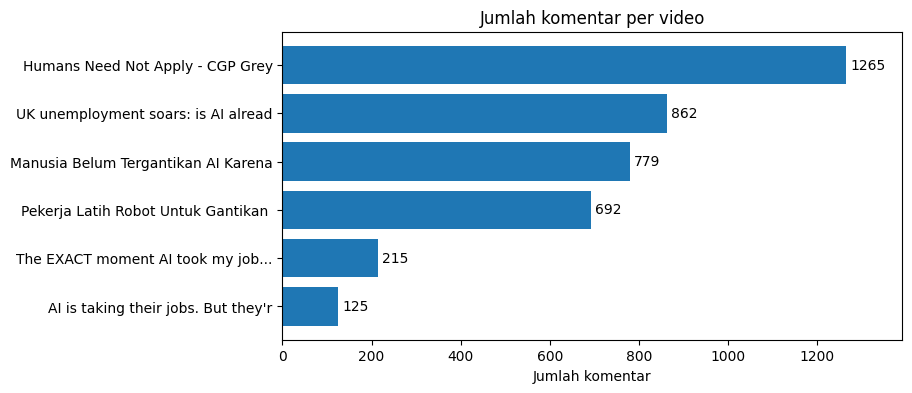

In [49]:
v = df_EDA["video_title"].value_counts().sort_values()

plt.figure(figsize=(8, 4))
batang = plt.barh(v.index.str[:35], v.values)
plt.bar_label(batang, padding=3)          # angka di ujung batang
plt.xlim(0, v.max() * 1.1)                # beri ruang supaya angka tidak terpotong
plt.title("Jumlah komentar per video")
plt.xlabel("Jumlah komentar")
plt.show()

Komposisi bahasa

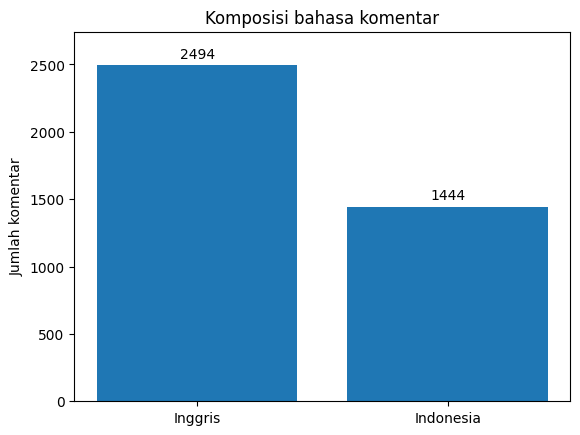

In [50]:
b = df_EDA["bahasa"].value_counts()

batang = plt.bar(b.index, b.values)
plt.bar_label(batang, padding=3)       # angka di atas batang
plt.ylim(0, b.max() * 1.1)             # beri ruang supaya angka tidak terpotong
plt.title("Komposisi bahasa komentar")
plt.ylabel("Jumlah komentar")
plt.show()

bahasa per video

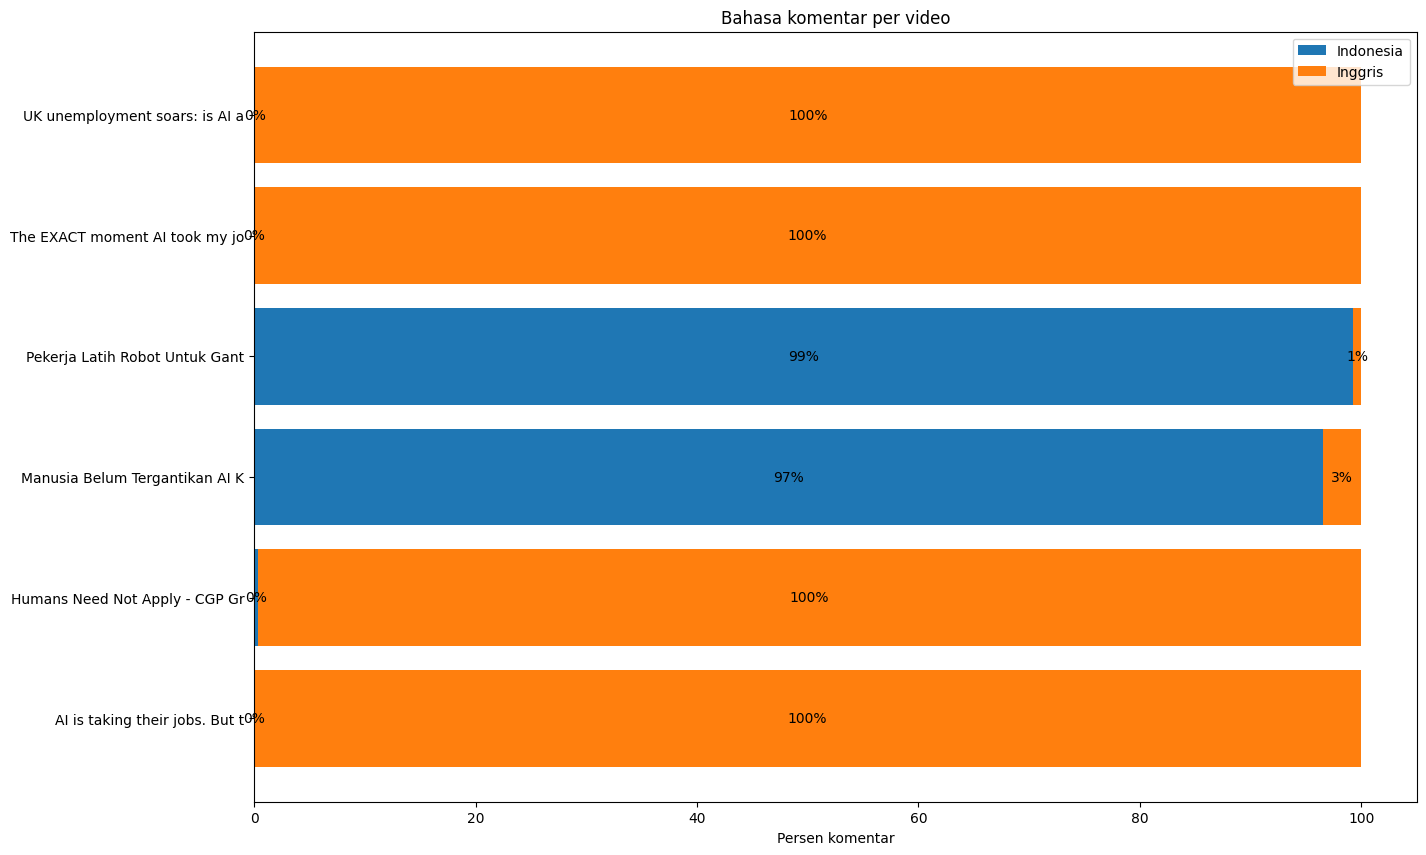

In [51]:
tabel = pd.crosstab(df_EDA["video_title"].str[:30], df["bahasa"])
persen = tabel.div(tabel.sum(axis=1), axis=0) * 100     # tiap video jadi 100%

kiri = 0
plt.figure(figsize=(15, 10))
for kolom in persen.columns:
    batang = plt.barh(persen.index, persen[kolom], left=kiri, label=kolom)
    plt.bar_label(batang, fmt="%.0f%%", label_type="center")
    kiri = kiri + persen[kolom]
plt.legend()
plt.xlabel("Persen komentar")
plt.title("Bahasa komentar per video")
plt.show()

panjang komentar

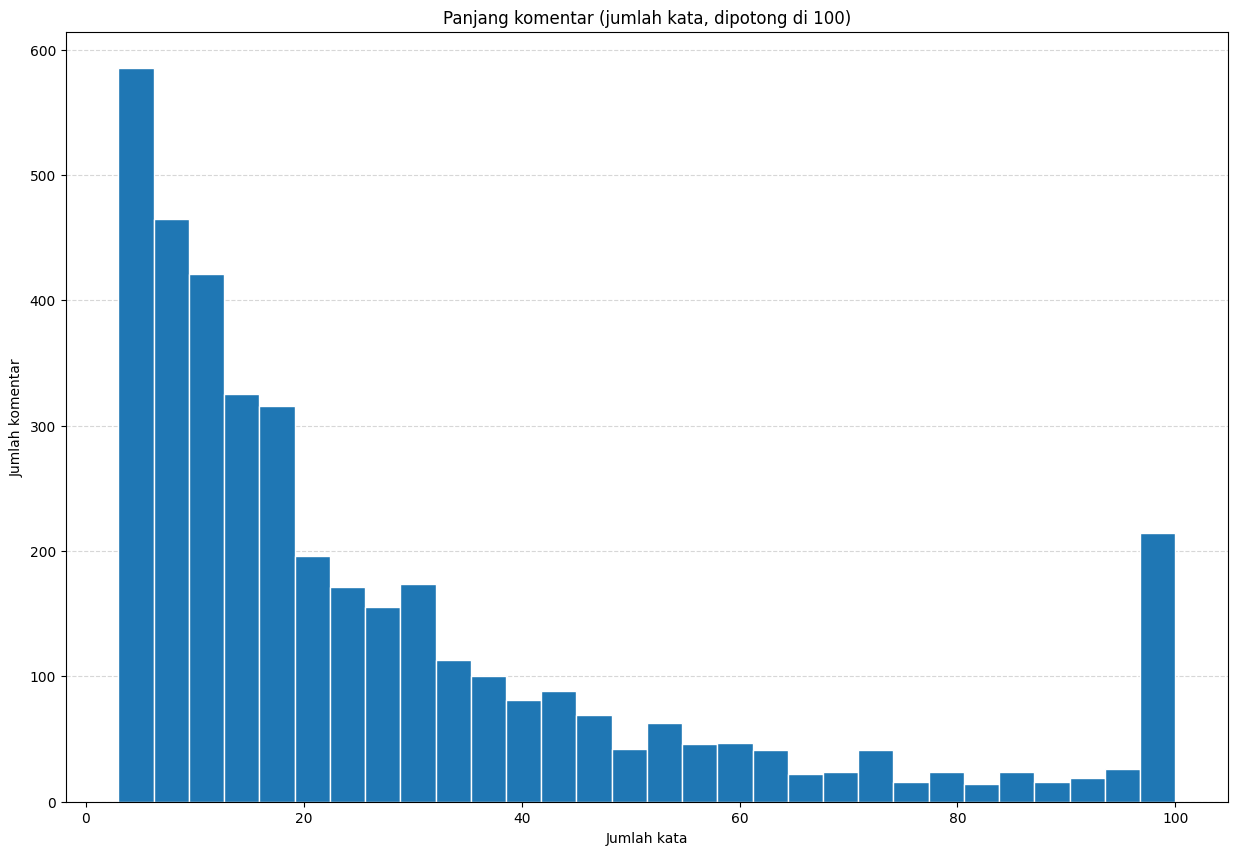

In [52]:
kata = df_EDA["comment"].str.split().str.len().clip(upper=100)

plt.figure(figsize=(15, 10))
plt.hist(kata, bins=30, edgecolor="white")
plt.grid(axis="y", linestyle="--", alpha=0.5)   # garis bantu mendatar
plt.gca().set_axisbelow(True)                   # garis di belakang batang
plt.title("Panjang komentar (jumlah kata, dipotong di 100)")
plt.xlabel("Jumlah kata")
plt.ylabel("Jumlah komentar")
plt.show()

emoji dan tanda

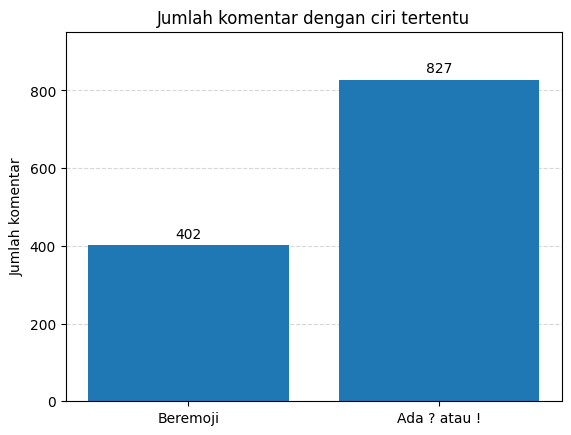

In [53]:
emoji = df_EDA["comment"].str.contains(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]").sum()
tanda = df_EDA["comment"].str.contains(r"[?!]").sum()

batang = plt.bar(["Beremoji", "Ada ? atau !"], [emoji, tanda])
plt.bar_label(batang, padding=3)
plt.ylim(0, max(emoji, tanda) * 1.15)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)
plt.title("Jumlah komentar dengan ciri tertentu")
plt.ylabel("Jumlah komentar")
plt.show()

# **5. Labeling**

Komentar dilabeli dengan LLM melalui API NVIDIA ke dalam empat kategori: **positif**, **negatif**, **netral**, dan **tidak relevan**. Dua model dibandingkan, yaitu **Nemotron 3 Ultra** dan **gpt-oss-20b**, masing-masing dengan **zero-shot** (hanya panduan) dan **few-shot** (panduan + contoh berlabel).

Pemilihan dilakukan pada bagian **dev** gold set. Konfigurasi terbaik kemudian diuji **sekali** pada bagian **test**, lalu dipakai untuk melabeli seluruh data.

## **5.1 Persiapan**

In [54]:
!pip install openai -q

In [55]:
import os
import time
import threading
import pandas as pd
import matplotlib.pyplot as plt
from openai import OpenAI, RateLimitError
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay

# Deteksi Google Colab vs VSCode untuk pengambilan API Key
api_key = None
if os.path.exists('/content'):
    try:
        from google.colab import userdata
        api_key = userdata.get("NVIDIA_API_KEY_NEMOTRON_3_ULTRA")
    except Exception as e:
        print(f"Catatan: Gagal memuat API Key dari Colab userdata: {e}")

if not api_key:
    # Ambil dari environment variable atau isi langsung jika di VSCode / lokal
    api_key = os.environ.get("NVIDIA_API_KEY_NEMOTRON_3_ULTRA", "YOUR_NVIDIA_API_KEY_HERE")

client = OpenAI(
    base_url="https://integrate.api.nvidia.com/v1",
    api_key=api_key,
)

MODEL_NEMOTRON = "nvidia/nemotron-3-ultra-550b-a55b"
MODEL_GPTOSS = "openai/gpt-oss-20b"
urutan = ["positif", "negatif", "netral", "tidak relevan"]


## **5.2 Gold Set**

Gold set berisi 150 komentar yang dilabeli manual. Data dibagi menjadi **test** (100 komentar pertama, hanya dipakai sekali di akhir) dan **dev** (50 komentar, dipakai untuk membandingkan model dan prompt).

In [56]:
# Deteksi lokasi pengambilan dataset gold set (Google Colab vs VSCode / Lokal)
if os.path.exists('/content/gold_set_final.csv'):
    # Google Colab
    path_gold = '/content/gold_set_final.csv'
elif os.path.exists('../../datasets/gold_set_final.csv'):
    # VSCode (dari folder notebook)
    path_gold = '../../datasets/gold_set_final.csv'
elif os.path.exists('datasets/gold_set_final.csv'):
    # VSCode (dari root project)
    path_gold = 'datasets/gold_set_final.csv'
else:
    path_gold = 'gold_set_final.csv'

g = pd.read_csv(path_gold)
print(f"Gold set dimuat dari: {path_gold} ({len(g)} baris)")

test = g.iloc[:100].reset_index(drop=True)
dev = g.iloc[100:].reset_index(drop=True)

print("test:", len(test), "| dev:", len(dev))
g["label"].value_counts()


test: 100 | dev: 50


,count
label,
tidak relevan,53
netral,40
negatif,31
positif,26


## **5.3 Panduan dan Contoh**

- `PANDUAN`: aturan pelabelan (sumbu B: apakah penulis melihat AI menggantikan pekerjaan sebagai ancaman). Dipakai sendirian pada **zero-shot**.
- `CONTOH2`: contoh berlabel yang diambil dari **luar** gold set. Ditambahkan ke panduan pada **few-shot**.

In [57]:
PANDUAN = """Tugas: tentukan sikap komentar YouTube terhadap isu AI yang menggantikan pekerjaan manusia.

Pertanyaan utama: penulis melihat AI menggantikan pekerjaan sebagai ancaman atau tidak?

Pilih satu label:
- positif: tidak merasa terancam, optimis, mendukung AI, mengajak belajar dan beradaptasi, atau berharap AI dipakai untuk meringankan pekerjaan. Termasuk komentar yang menunjukkan kelemahan AI sehingga tidak takut, atau membantah bahwa AI akan menggantikan manusia.
- negatif: merasa terancam, takut kehilangan pekerjaan, atau memperingatkan bahaya AI bagi manusia
- netral: membahas AI, robot, otomasi, atau pekerjaan tanpa memihak, termasuk candaan tentang kemampuan AI atau robot
- tidak relevan: tidak membahas AI, robot, otomasi, atau pekerjaan

Jawab satu label saja, tanpa penjelasan."""

In [58]:
CONTOH = """Contoh:
Komentar: I mean, a robot doesnt need money, doesn't have emotions (yet), so yeah, of course a robot boss would be the best bos
Label: netral

Komentar: Hmm.. Bisa ngga ya AI menggantikan seluruh pejabat di pemerintahan Konoha dari kepala sampai kaki..?
Label: netral

Komentar: Meanwhile in konoha, gen-z pilih2 atau bahkan nolak kerjaan Krn gaji kecil..😊 .. btw..gw masih dukung buat yg mau kabur ke LN, kalau bisa secepatnya lah kalian pada kabur 😁
Label: tidak relevan

Komentar: in fact most 'accidents' aren't even accidents at all. Most of them are due to the way that street was designed, if the semaphores are smart of not, how strict are regulations etc, i.e.: they are life sentences because depending on the way a street was designed theyre unavoiadable (im looking at you american stroads with cars speeding inside cities
Label: tidak relevan

Komentar: bahkan alam aja sudah berusaha melindungi manusia dari kepunahan dengan cara menghalangi/menghambat energi sebanyak itu untuk bisa digunakan pengembangan AI
Label: negatif

Komentar: Pull the fucking plug. Nobody wants AI
Label: negatif

Komentar: As an AI engineer I’ll say, these systems are only as good as the data and governance behind them, and most companies are skipping that part. Leaders are rushing to plug in third party tools, trusting outputs they don’t fully understand, and calling it transformation. Sure, you see efficiency at the individual level. But at the enterprise level? Not much. What I see is technical debt building fast. People are spinning up agents with no lifecycle plan, no monitoring, no real ownership. That doesn’t disappear. It compounds. AI absolutely cuts lower end roles and creates efficiency. But it also increases reliance on high end expertise and long term maintenance. The cost doesn’t go away, it just shifts up the chain. There’s no free lunch.
Label: positif

Komentar: Konten ini mengatakan betapa CERDAS DAN MENAKUTKANNYA AI. Kecerdasan AI setara dokto matematika Tapi LUCUNYA dia mengatakan satu satunya masalah AI sekarang adalah : energi . AI butuh energi yang besar. Apakah AI tidak bisa MEMAKAI SEGALA KECERDASAN YANG DI GEMABR GEMBORKA ITU MENCONTEK CARA KERJA OTAK MANUSIA DALAM EFESIENSI ENERGI JADI MASALAH ENERGI YANG BELUM TERSELESAIKAN: ITU KONTRADIKSI DENGAN MENGATAKAN GEMBAR GEMBOR KECERDASAN AI
Label: positif"""

In [59]:
CONTOH2 = CONTOH + """

Komentar: Ada quantum computing. Kalau AI digabung dgn quantum computing?
Label: netral

Komentar: Bang bahkan baru² ini di Indonesia udh ada video tukang martabak yg dipakein kamera di topinya buat ai pelajarin
Label: netral"""

FEWSHOT = PANDUAN + "\n\n" + CONTOH2

In [60]:
# Empat konfigurasi yang dibandingkan: (panduan, model)
pengaturan = {
    "Nemotron | zero-shot": (PANDUAN, MODEL_NEMOTRON),
    "Nemotron | few-shot": (FEWSHOT, MODEL_NEMOTRON),
    "gpt-oss | zero-shot": (PANDUAN, MODEL_GPTOSS),
    "gpt-oss | few-shot": (FEWSHOT, MODEL_GPTOSS),
}

## **5.4 Fungsi Pelabelan dan Penilaian**

- `label_llm`: mengirim satu komentar ke LLM dan mengembalikan satu label.
- Kalau kena batas permintaan (error 429), koneksi putus, *timeout*, atau server NVIDIA sedang error (5xx), fungsi **menunggu lalu mencoba lagi tanpa batas jumlah percobaan**. Jedanya naik bertahap (30, 60, 120, ... paling lama 300 detik), jadi proses panjang tidak berhenti hanya karena limit sesaat. Error yang tidak akan sembuh dengan menunggu (misalnya API key salah) tetap dihentikan supaya langsung ketahuan.
- `tanya_llm` mengembalikan jawaban mentah LLM, `ambil_label` mengambil labelnya. Keduanya dipisah supaya jawaban mentah bisa disimpan di 5.8 untuk dicek ulang.
- Mode berpikir Nemotron dimatikan, sedangkan gpt-oss (model penalaran) diberi batas token lebih besar agar sempat menyelesaikan prosesnya sebelum menjawab. Aturan pelabelannya tetap sama untuk semua model.

In [ ]:
from openai import APIConnectionError, InternalServerError

# Retry diatur sendiri di tanya_llm, jadi retry bawaan library dimatikan; timeout supaya tidak menggantung selamanya
client = client.with_options(timeout=60, max_retries=0)

LABEL_VALID = ["tidak relevan", "positif", "negatif", "netral"]


def tanya_llm(komentar, panduan, model):
    """Kirim satu komentar ke LLM dan kembalikan jawaban mentahnya (huruf kecil)."""
    tambahan = {}
    if "nemotron" in model:
        tambahan = {"chat_template_kwargs": {"enable_thinking": False}}

    batas_token = 10
    if "gpt-oss" in model:
        batas_token = 300        # model penalaran butuh ruang berpikir dulu

    coba = 0
    while True:                  # tanpa batas percobaan: tunggu lalu ulangi sampai berhasil
        try:
            jawaban = client.chat.completions.create(
                model=model,
                messages=[{"role": "system", "content": panduan},
                          {"role": "user", "content": f"Komentar: {komentar}\nLabel:"}],
                temperature=0,
                max_tokens=batas_token,
                extra_body=tambahan,
            )
            return (jawaban.choices[0].message.content or "").strip().lower()
        except (RateLimitError, APIConnectionError, InternalServerError) as e:
            jeda = min(30 * 2 ** coba, 300)      # 30, 60, 120, 240, 300, 300, ...
            coba += 1
            print(f"{type(e).__name__} (percobaan ke-{coba}), tunggu {jeda} detik lalu coba lagi...")
            time.sleep(jeda)


def ambil_label(hasil):
    """Ambil label dari jawaban LLM; None kalau tidak ada label yang dikenali."""
    for lab in LABEL_VALID:
        if lab in hasil:
            return lab
    return None


def label_llm(komentar, panduan, model):
    return ambil_label(tanya_llm(komentar, panduan, model)) or "tidak relevan"

In [62]:
skor = {}
semua_prediksi = {}

def uji(nama):
    panduan, model = pengaturan[nama]
    prediksi = []
    for komentar in dev["comment"]:
        prediksi.append(label_llm(komentar, panduan, model))
        time.sleep(3)          # jaga batas permintaan
    skor[nama] = round(f1_score(dev["label"], prediksi, average="macro"), 3)
    semua_prediksi[nama] = prediksi
    print(nama, "| macro-F1 =", skor[nama])
    print(classification_report(dev["label"], prediksi, zero_division=0))


def tampilkan_matrix(nama):
    ConfusionMatrixDisplay.from_predictions(dev["label"], semua_prediksi[nama], labels=urutan, cmap="Blues")
    plt.title(f"Confusion matrix (dev): {nama}")
    plt.xlabel("Prediksi LLM")
    plt.ylabel("Label manual")
    plt.show()


def grafik_skor(daftar_nama, judul):
    nilai = [skor[n] for n in daftar_nama]
    plt.figure(figsize=(8, 4))
    batang = plt.bar(daftar_nama, nilai)
    plt.bar_label(batang, fmt="%.3f", padding=3)
    plt.ylim(0, 1)
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.gca().set_axisbelow(True)
    plt.title(judul)
    plt.ylabel("macro-F1 (dev)")
    plt.show()

## **5.5 Nemotron 3 Ultra**

### **1. Zero-shot**

In [63]:
uji("Nemotron | zero-shot")

Nemotron | zero-shot | macro-F1 = 0.464
               precision    recall  f1-score   support

      negatif       0.38      0.75      0.50         8
       netral       0.20      0.13      0.16        15
      positif       0.80      0.50      0.62         8
tidak relevan       0.58      0.58      0.58        19

     accuracy                           0.46        50
    macro avg       0.49      0.49      0.46        50
 weighted avg       0.47      0.46      0.45        50



### **2. Confusion matrix zero-shot**

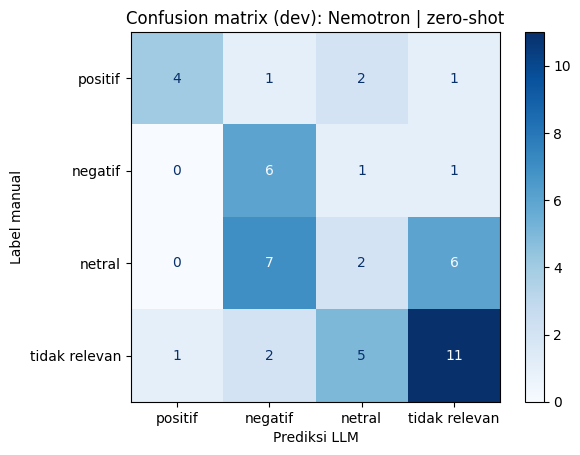

In [64]:
tampilkan_matrix("Nemotron | zero-shot")

### **3. Few-shot**

In [65]:
uji("Nemotron | few-shot")

Nemotron | few-shot | macro-F1 = 0.518
               precision    recall  f1-score   support

      negatif       0.42      0.62      0.50         8
       netral       0.45      0.33      0.38        15
      positif       0.50      0.75      0.60         8
tidak relevan       0.67      0.53      0.59        19

     accuracy                           0.52        50
    macro avg       0.51      0.56      0.52        50
 weighted avg       0.54      0.52      0.51        50



### **4. Confusion matrix few-shot**

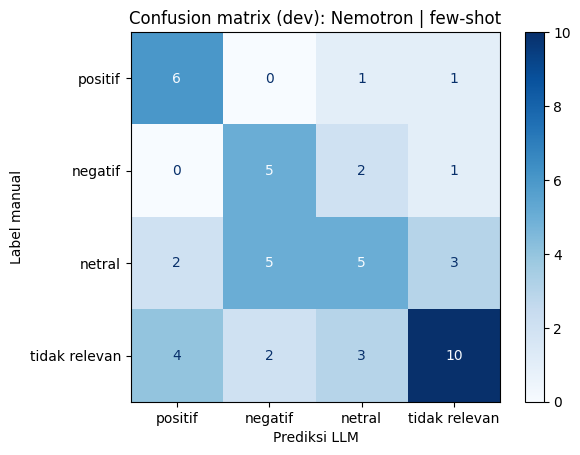

In [66]:
tampilkan_matrix("Nemotron | few-shot")

### **5. Perbandingan zero-shot dan few-shot**

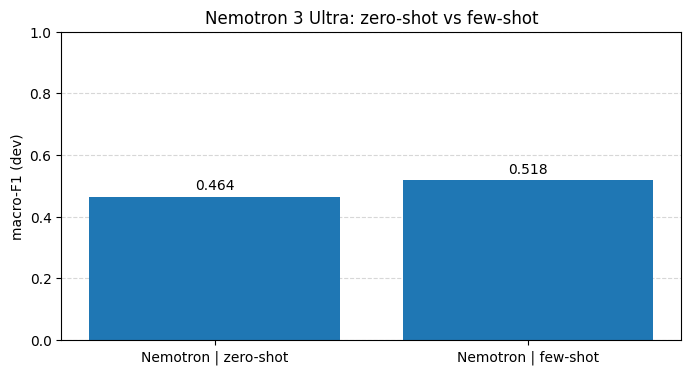

In [67]:
grafik_skor(["Nemotron | zero-shot", "Nemotron | few-shot"], "Nemotron 3 Ultra: zero-shot vs few-shot")

## **5.6 gpt-oss-20b**

gpt-oss adalah model penalaran, jadi setiap komentar sedikit lebih lama diproses.

### **6. Zero-shot**

In [ ]:
uji("gpt-oss | zero-shot")

### **7. Confusion matrix zero-shot**

In [ ]:
tampilkan_matrix("gpt-oss | zero-shot")

### **8. Few-shot**

In [ ]:
uji("gpt-oss | few-shot")

In [ ]:
tampilkan_matrix("gpt-oss | few-shot")

### **9. Perbandingan zero-shot dan few-shot**

In [ ]:
grafik_skor(["gpt-oss | zero-shot", "gpt-oss | few-shot"], "gpt-oss-20b: zero-shot vs few-shot")

## **5.7 Perbandingan Akhir dan Pemilihan Konfigurasi**

### **10. Bandingkan keempat konfigurasi**

Konfigurasi dengan macro-F1 dev tertinggi dipilih. Dev hanya 50 komentar, sehingga selisih kurang dari sekitar 0,03 sebaiknya dianggap seri. Kalau seri, konfigurasi yang lebih sederhana atau lebih cepat boleh dipilih secara manual.

In [ ]:
grafik_skor(list(pengaturan.keys()), "Perbandingan semua konfigurasi")

In [ ]:
terbaik = max(skor, key=skor.get)
# terbaik = "Nemotron | zero-shot"     # aktifkan baris ini kalau ingin memilih manual

panduan_terbaik, model_terbaik = pengaturan[terbaik]
print("Konfigurasi terpilih:", terbaik, "| macro-F1 dev =", skor[terbaik])

### **Uji sekali pada data test**

Data test belum pernah dipakai saat memilih model, sehingga angka ini yang dilaporkan sebagai kinerja pelabel.

In [ ]:
prediksi_test = []
for komentar in test["comment"]:
    prediksi_test.append(label_llm(komentar, panduan_terbaik, model_terbaik))
    time.sleep(3)

print(terbaik, "| macro-F1 test =", round(f1_score(test["label"], prediksi_test, average="macro"), 3))
print(classification_report(test["label"], prediksi_test, zero_division=0))

ConfusionMatrixDisplay.from_predictions(test["label"], prediksi_test, labels=urutan, cmap="Blues")
plt.title(f"Confusion matrix (test): {terbaik}")
plt.xlabel("Prediksi LLM")
plt.ylabel("Label manual")
plt.show()

## **5.8 Pelabelan Seluruh Data**

Seluruh komentar di `youtube_comments_clean_EDA.csv` dilabeli dengan konfigurasi terpilih dalam **sekali jalan**. Sel ini cukup dijalankan satu kali lalu dibiarkan sampai selesai.

- **Tidak berhenti karena limit.** `label_llm` (5.4) menunggu lalu mencoba lagi tanpa batas kalau kena limit atau error jaringan.
- **Kecepatan.** Permintaan dikirim oleh `JUMLAH_PEKERJA` pekerja sekaligus, tetapi jarak antar permintaan tetap dijaga minimal `JEDA_PERMINTAAN` detik (sekitar 37 permintaan per menit). Dengan begitu waktu tunggu jawaban LLM tidak ikut memperlambat, dan 3.938 komentar selesai sekitar **1 jam 45 menit** bila tidak sering kena limit. Kalau ternyata masih sering kena 429, naikkan `JEDA_PERMINTAAN` (misalnya ke 2).
- **Checkpoint setiap komentar.** Tiap hasil langsung ditulis ke `label_sementara.csv` bersama nomor baris, isi komentar, dan jawaban mentah LLM. Kalau proses terputus (sel dihentikan, internet mati, Colab restart), jalankan sel ini lagi dan pelabelan dilanjutkan dari komentar yang belum dilabeli, tanpa ada yang hilang. Isi komentar di checkpoint dicocokkan dengan data, jadi label tidak mungkin tergeser ke komentar yang salah.
- **Konfigurasi.** `KONFIGURASI` otomatis memakai hasil 5.7 (`terbaik`). Kalau runtime sempat restart, cukup jalankan sel 5.1 sampai 5.4 lalu sel ini; konfigurasi diisi dari nilai cadangan di baris `KONFIGURASI` (ubah kalau pilihanmu berbeda).
- File di Colab hilang saat sesi berakhir, jadi unduh `label_sementara.csv` sesekali kalau prosesnya panjang.

In [ ]:
import csv
from concurrent.futures import ThreadPoolExecutor, as_completed

# ===== Pengaturan =====
KONFIGURASI = globals().get("terbaik", "Nemotron | few-shot")   # cadangan bila 5.5-5.7 tidak dijalankan ulang
JEDA_PERMINTAAN = 1.6        # detik minimal antar permintaan (sekitar 37 per menit)
JUMLAH_PEKERJA = 3           # permintaan yang boleh berjalan bersamaan

panduan_pakai, model_pakai = pengaturan[KONFIGURASI]
print("Konfigurasi pelabel:", KONFIGURASI)

# Deteksi lokasi pengambilan dataset untuk pelabelan (Google Colab vs VSCode / Lokal)
if os.path.exists('/content/youtube_comments_clean_EDA.csv'):
    # Google Colab
    path_clean = '/content/youtube_comments_clean_EDA.csv'
    FILE_SEMENTARA = '/content/label_sementara.csv'
elif os.path.exists('../../datasets/youtube_comments_clean_EDA.csv'):
    # VSCode (dari folder notebook)
    path_clean = '../../datasets/youtube_comments_clean_EDA.csv'
    FILE_SEMENTARA = '../../datasets/label_sementara.csv'
elif os.path.exists('../../datasets/youtube_comments_clean.csv'):
    # Fallback ke dataset clean yang ada di folder datasets
    path_clean = '../../datasets/youtube_comments_clean.csv'
    FILE_SEMENTARA = '../../datasets/label_sementara.csv'
elif os.path.exists('datasets/youtube_comments_clean_EDA.csv'):
    # VSCode (dari root project)
    path_clean = 'datasets/youtube_comments_clean_EDA.csv'
    FILE_SEMENTARA = 'datasets/label_sementara.csv'
elif os.path.exists('datasets/youtube_comments_clean.csv'):
    path_clean = 'datasets/youtube_comments_clean.csv'
    FILE_SEMENTARA = 'datasets/label_sementara.csv'
else:
    path_clean = 'youtube_comments_clean_EDA.csv'
    FILE_SEMENTARA = 'label_sementara.csv'

data = pd.read_csv(path_clean)
komentar_data = data["comment"].fillna("").astype(str)
print(f"Data pelabelan dimuat dari: {path_clean} ({len(data)} baris)")

KOLOM_CHECKPOINT = ["id", "comment", "label", "jawaban_mentah"]


def baca_checkpoint():
    """Baca checkpoint dan pastikan setiap label menempel pada komentar yang benar."""
    if not os.path.exists(FILE_SEMENTARA):
        return pd.DataFrame(columns=KOLOM_CHECKPOINT)
    cp = pd.read_csv(FILE_SEMENTARA, dtype=str, keep_default_na=False)
    if "id" not in cp.columns:
        # Format lama (hanya kolom label, berurutan dari baris 0): ubah ke format baru
        cp = pd.DataFrame({"id": range(len(cp)), "comment": komentar_data.iloc[:len(cp)].values,
                           "label": cp["label"].values, "jawaban_mentah": ""})
        cp.to_csv(FILE_SEMENTARA, index=False)
        print("Checkpoint format lama diubah ke format baru.")
    cp["id"] = cp["id"].astype(int)
    cp = cp.drop_duplicates("id", keep="last").set_index("id").sort_index()
    beda = cp.index[cp["comment"].values != komentar_data.loc[cp.index].values]
    if len(beda) > 0:
        raise ValueError(f"{len(beda)} komentar di {FILE_SEMENTARA} tidak cocok dengan data (contoh id {list(beda[:5])}). "
                         "Data bersih sudah berubah sejak checkpoint dibuat; hapus/ganti nama checkpoint lalu ulangi.")
    return cp


# Lanjutkan dari hasil sebelumnya kalau ada
checkpoint = baca_checkpoint()
sisa = [i for i in range(len(data)) if i not in checkpoint.index]
print(f"Sudah dilabeli: {len(checkpoint)} | sisa: {len(sisa)} dari {len(data)}")

# Penjaga jarak antar permintaan, dipakai bersama oleh semua pekerja
kunci_jeda = threading.Lock()
giliran_berikut = [time.monotonic()]


def tunggu_giliran():
    with kunci_jeda:
        mulai = max(time.monotonic(), giliran_berikut[0])
        giliran_berikut[0] = mulai + JEDA_PERMINTAAN
    time.sleep(max(0, mulai - time.monotonic()))


def kerjakan(i):
    tunggu_giliran()
    return i, tanya_llm(komentar_data.iloc[i], panduan_pakai, model_pakai)


if sisa:
    waktu_mulai = time.time()
    file_baru = not os.path.exists(FILE_SEMENTARA)
    with open(FILE_SEMENTARA, "a", newline="", encoding="utf-8") as f:
        tulis = csv.writer(f)
        if file_baru:
            tulis.writerow(KOLOM_CHECKPOINT)
        pelaksana = ThreadPoolExecutor(JUMLAH_PEKERJA)
        tugas = [pelaksana.submit(kerjakan, i) for i in sisa]
        try:
            for n, selesai in enumerate(as_completed(tugas), 1):
                i, mentah = selesai.result()
                tulis.writerow([i, komentar_data.iloc[i], ambil_label(mentah) or "tidak relevan", mentah])
                f.flush()                           # langsung tersimpan, tidak ada yang hilang kalau terputus
                if n % 50 == 0 or n == len(sisa):
                    lewat = time.time() - waktu_mulai
                    perkiraan = lewat / n * (len(sisa) - n)
                    print(f"{len(checkpoint) + n} / {len(data)} selesai | "
                          f"berjalan {lewat / 60:.0f} menit | perkiraan sisa {perkiraan / 60:.0f} menit")
        except BaseException:
            # Sel dihentikan atau ada error yang tidak bisa diulang: batalkan antrean supaya tidak jalan di belakang
            for t in tugas:
                t.cancel()
            print("Dihentikan. Semua hasil sampai titik ini sudah tersimpan; jalankan sel ini lagi untuk melanjutkan.")
            raise
        finally:
            pelaksana.shutdown(wait=True, cancel_futures=True)

checkpoint = baca_checkpoint()
assert len(checkpoint) == len(data), "Masih ada komentar yang belum dilabeli; jalankan sel ini lagi."
label_semua = checkpoint.loc[range(len(data)), "label"].tolist()

tak_terbaca = (checkpoint["jawaban_mentah"] != "") & checkpoint["jawaban_mentah"].map(ambil_label).isna()
print("Selesai:", len(label_semua), "komentar")
print("Jawaban LLM tanpa label yang dikenali (otomatis jadi 'tidak relevan'):", int(tak_terbaca.sum()))

In [ ]:
data["label"] = label_semua
data["label"].value_counts()

In [ ]:
# Simpan hasil pelabelan akhir (Google Colab vs VSCode / Lokal)
if os.path.exists('/content'):
    # Google Colab
    output_path = '/content/youtube_comments_gold.csv'
    data.to_csv(output_path, index=False)
    print(f"Hasil pelabelan disimpan di Colab: {output_path}")
    try:
        from google.colab import files
        files.download(output_path)
    except Exception as e:
        print(f"Download otomatis browser dilewati: {e}")
else:
    # VSCode / Lingkungan Lokal: simpan ke folder datasets
    if os.path.exists('../../datasets'):
        output_path = '../../datasets/youtube_comments_gold.csv'
    elif os.path.exists('datasets'):
        output_path = 'datasets/youtube_comments_gold.csv'
    else:
        output_path = 'youtube_comments_gold.csv'

    data.to_csv(output_path, index=False)
    print(f"Hasil pelabelan berhasil disimpan di folder datasets: {output_path}")
